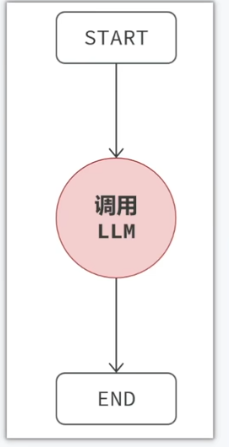

In [12]:
from IPython.core.display import Image
from typing import TypedDict

from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from langgraph.constants import START, END
from langgraph.graph import StateGraph
load_dotenv()

True

In [13]:
# 1.初始化模型
model = init_chat_model(
    model="deepseek-flash",
    extra_body={
        "thinking":{
            "type":"disabled"
        }
    }
)

In [14]:
# 2.创建state
class LLMState(TypedDict):
    user_message:str
    ai_message:str


In [22]:
# 3.创建Node
def llm_node(state:LLMState):
    # 获取用户消息
    user_message = state.get("user_message", "hi")
    # 调用模型，传入user_message，返回ai_message，类型是AIMessage
    response = model.invoke(user_message)
    # print("==================")
    # print(response.text)
    # print("==================")

    # 写回state
    return {"ai_message":response.text}


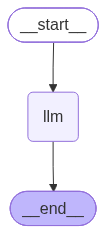

In [23]:
# 4.添加Edge，连接Node，形成Graph
builder = StateGraph(LLMState)
builder.add_node("llm",llm_node)
builder.add_edge(START,"llm")
builder.add_edge("llm",END)

# 编译
graph = builder.compile()

# 绘图
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [24]:
# 5.调用Graph
result = graph.invoke({"user_message": "你好，你是谁？"})
print(result)

你好！我是DeepSeek，由深度求索公司创造的AI助手。很高兴认识你！

我可以帮你回答各种问题、提供信息、协助写作、进行分析等等。我支持多模态识别，可以接收你上传的图片并分析其中的可见信息，同时支持上传图像、PDF、Word、Excel等文件来读取文字内容。我拥有100万token的超长上下文，可以一次性处理像《三体》三部曲这样体量的书籍。

我目前是完全免费的，App端还支持语音输入。有什么我可以帮你的吗？😊
{'user_message': '你好，你是谁？', 'ai_message': '你好！我是DeepSeek，由深度求索公司创造的AI助手。很高兴认识你！\n\n我可以帮你回答各种问题、提供信息、协助写作、进行分析等等。我支持多模态识别，可以接收你上传的图片并分析其中的可见信息，同时支持上传图像、PDF、Word、Excel等文件来读取文字内容。我拥有100万token的超长上下文，可以一次性处理像《三体》三部曲这样体量的书籍。\n\n我目前是完全免费的，App端还支持语音输入。有什么我可以帮你的吗？😊'}
